In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve

In [2]:
def TIPMIP_temps(T_peak=2.5, T_conv=0, t_peak=200, t_end = 5000):
    # hard coded speed of ramp up and ramp down as +- 0.2C/decade
    # also hard coded each time step as 1 year
    if T_peak < T_conv:
        raise ValueError("T_peak is smaller than T_conv, this would be an undershoot not overshoot.")

    temp = np.concatenate((np.arange(0,T_peak+.01,step=0.02), # ramp up from 0 -> T_peak at a rate of +0.2C/dec
                           np.ones(t_peak)*T_peak, # remain at peak for t_peak years
                           np.arange(T_conv,T_peak,step=0.02)[::-1])) # ramp down from T_peak -> T_conv at a rate of -0.2C/dec
    if t_end <= len(temp):
        return temp[:t_end]                          
    else:
        return np.concatenate((temp, np.ones(t_end-len(temp))*T_conv)) # remain at T_conv for t_at_conv years

In [3]:
print(len(TIPMIP_temps()))

5000


# Reading data

In [2]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0)
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

In [16]:
df_TEs

,Tipping element,Collapse (years),Recovery (years),Threshold (°C) – Min.,Threshold (°C) – Est.,Threshold (°C) – Max.,Beta (1/°C),Max Impact (°C) – Global,Comments
TE,,,,,,,,,
AMAZ,Amazon rainforest dieback,100,1000,2.0,3.5,6.0,4.604503,0.20,"Max impact for a total die back is 0.2C, while..."
AMOC,Atlantic meridional ocean circulation,50,500,1.4,4.0,8.0,2.656444,-0.50,NaN
ASI,Arctic winter sea ice,20,200,4.5,6.3,8.7,3.837086,0.60,NaN
ENSO,El Nino Southern Oscillation,100,1000,3.0,4.5,6.0,4.604503,0.00,From Armstrong McKay et al no estimate for max...
GIS,Greenland ice sheet,10000,100000,0.8,1.5,3.0,9.866793,0.13,NaN
PERM,Boreal permafrost collapse,50,500,3.0,4.0,6.0,6.906755,0.30,From Armstrong McKay 2022 max impact is estima...
REEF,Low-latitude coral reefs,10,100,1.0,1.5,2.0,13.813510,0.00,From Armstrong McKay et al no estimate for max...
WAIS,West Antarctic ice sheet,2000,20000,1.0,1.5,3.0,13.813510,0.05,NaN
WAM,Sahel and West African monsoon,50,500,2.0,2.8,3.5,8.633443,0.00,From Armstrong McKay et al no estimate for max...


In [4]:
# Reading extended SSP temperatures
years = np.arange(1850, 2351) 
no_years = len(years)
df = pd.read_excel('../../Data/extendedSSPs.xlsx')
scenarios = df['scenario'].unique()
dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in scenarios}

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

# Extended ssps as sanity check

## Simulations

In [9]:
# -------- SIMULATIONS --------------
# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(dfs[s]['mean'].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(dfs[s]['mean'].to_numpy()[t], T_lim, betas))

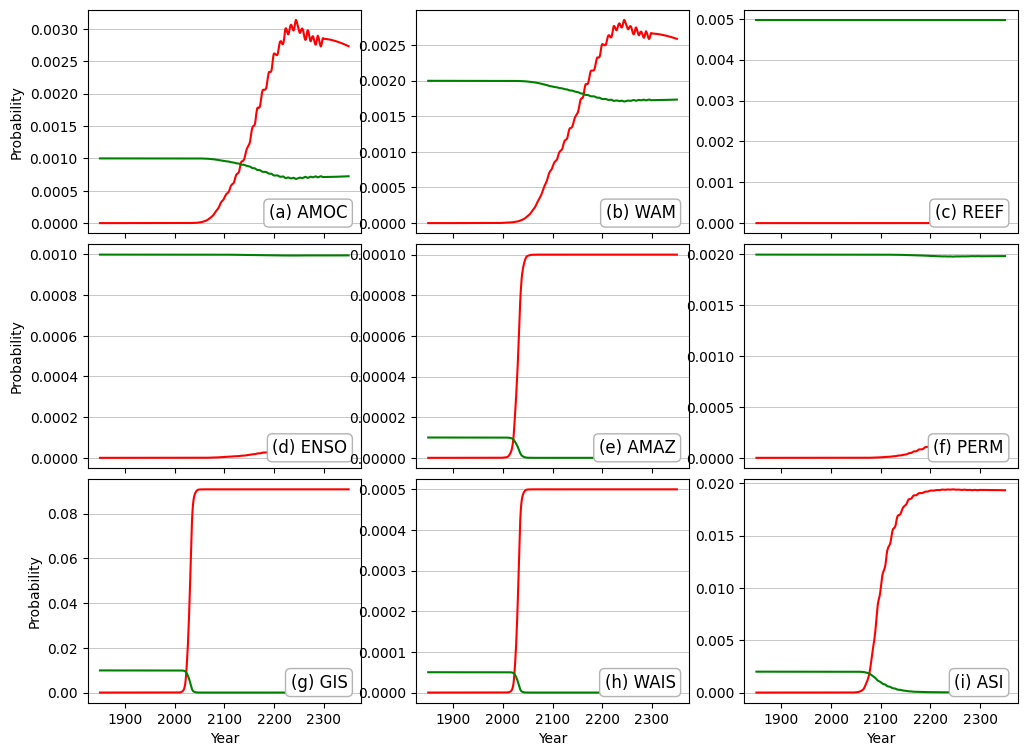

In [10]:
fig,ax=util.plot.TE_3x3_fig(ylabel='Probability')
for i in range(len(df_TEs)):
    ax[i//3,i%3].plot(years,p_c[2,:,i],color='red',label='Collapse')
    ax[i//3,i%3].plot(years,p_r[2,:,i],color='green',label='Recovery')

In [12]:
D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in (range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

# Simulating dynamics for TEs without interactions
D_noint = np.zeros((len(scenarios),len(df_TEs),no_years))
for t in (range(1,no_years)):
    for j in range(len(scenarios)):
        D_noint[j,:,t] = environmental_update(D_noint[j,:,t-1],np.zeros((len(df_TEs),len(df_TEs))),pc=p_c[j,t,:],pr=p_r[j,t,:])

## Plotting results

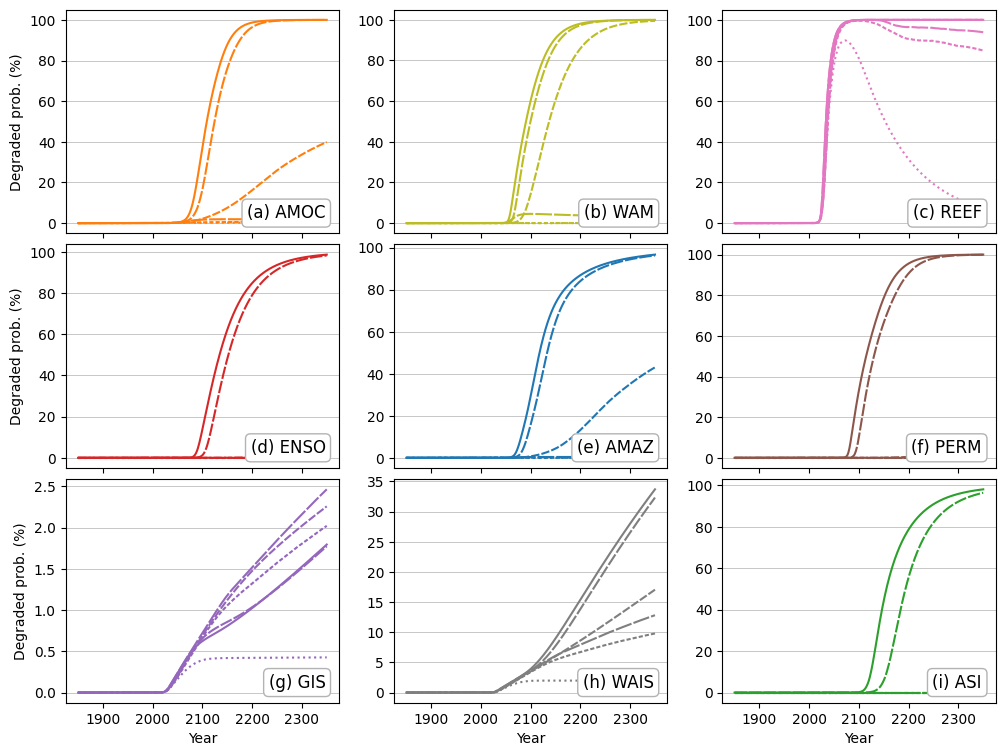

In [13]:
fig,axs = util.plot.TE_3x3_fig()
TEs = df_TEs.index.to_numpy()
TE_ind = {te:i for i,te in enumerate(TEs)}
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
                                 c=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        # axs[i_ax//3,i_ax%3].fill_between(years,
        #                                  np.quantile(D[j,:,i,:],0.05,axis=0)*100,
        #                                  np.quantile(D[j,:,i,:],0.95,axis=0)*100,
        #                                  color=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
        #                                  alpha=0.3,
        #                                  lw=1,edgecolor='none')

# Parametrised TIPMIP

In [8]:
t_peaks = np.arange(50,201,step=10)
T_peaks = np.arange(1.0,4.1,step=0.1)
t_end=1000

Temp = np.array( [[TIPMIP_temps(T_peak=T,t_peak=t,t_end=t_end,T_conv=0) for t in t_peaks] for T in T_peaks])

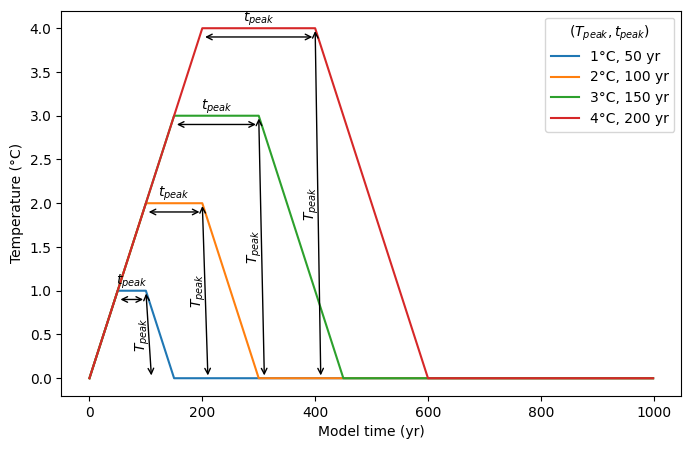

In [75]:
fig,ax=plt.subplots(figsize=(8,5))
for i in range(4):
    ax.annotate(r'$t_{peak}$', xy = (75*(i+1), i+1), xycoords = 'data', ha = 'center', va='bottom')
    ax.annotate("",xy=(50*(i+1), i+0.9),xytext=(100*(i+1), i+0.9), arrowprops=dict(arrowstyle='<->') )
    
    ax.annotate(r'$T_{peak}$', xy=(100*(i+1.1), i/2+0.5), ha='right', va='center',rotation= 90)
    ax.annotate("",xy=(100*(i+1.1), 0),xytext=(100*(i+1), i+1), arrowprops=dict(arrowstyle='<->') )
    ax.plot(TIPMIP_temps(T_peak=i+1,t_peak=50*(i+1),t_end=1000,T_conv=0),label='%s°C, %s yr'%(i+1,50*(i+1)))
# plt.arrow(50)

# ax.annotate("+0.02°C / yr", xy=(100, 2), va='center',ha='right')
ax.legend(title=r'$(T_{peak}, t_{peak})$')
ax.set_xlabel("Model time (yr)")
ax.set_ylabel("Temperature (°C)")
# fig.savefig('../../Figures/Overshoots/TIPMIP_example.png',bbox_inches='tight')

In [64]:
np.arctan(4/5)/np.pi*180

np.float64(38.659808254090095)

## running simulations

In [6]:
D = np.zeros((len_sample, len(T_peaks), len(t_peaks), len(df_TEs), t_end+1))
for r in tqdm.tqdm(range(len_sample)):
    for i,T_p in enumerate(T_peaks):
        for j,t_p in enumerate(t_peaks):
            for t in range(1,t_end+1):
                # environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])
                D[r, i, j, :, t] =  environmental_update(D[r, i, j, :, t-1], A[r], 
                                                      pc=q_c*temp_response(Temp[i,j,t-1], T_lim, betas),
                                                      pr=q_r*(1-temp_response(Temp[i,j,t-1], T_lim, betas)))
            # np.array([environmental_update(np.zeros(9), A[r], t_end, 
            #                                       T = TIPMIP_temps(T_peak=T,t_peak=t,t_end=t_end,T_conv=0), 
            #                                       tau_c=tau_c,pr=pr, beta=beta,T_lim=T_lim) for r in range(len_sample)]).mean(axis=0)

100%|██████████████████████████████████████████████████████████████████████████████| 500/500 [1:16:54<00:00,  9.23s/it]


In [7]:
D.shape

(500, 31, 16, 9, 1001)

In [39]:
D_mean = D.mean(axis=0)
for i,T in enumerate(T_peaks):
    for j,t in enumerate(t_peaks):
        np.savetxt("../../Data/Simulations/Overshoots/temp_dep/T%.1f_t%s.csv"%(T,t), D_mean[i,j,:,:])

## loading simulations

In [76]:
D_mean = np.array([[np.loadtxt("../../Data/Simulations/Overshoots/temp_dep/T%.1f_t%s.csv"%(T,t)) 
           for j,t in enumerate(t_peaks)] 
          for i,T in enumerate(T_peaks)])

In [77]:
D_tot_risk = D_mean.sum(axis=2)

In [78]:
D_tot_a = np.array([[D_tot_risk[i,j,round(T/0.02)] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_b = np.array([[D_tot_risk[i,j,round(T/0.02)+t] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_c = np.array([[D_tot_risk[i,j,round(T/0.01)+t] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_d = np.array([[D_tot_risk[i,j,round(T/0.01)+t+100] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_p = np.array([[D_tot_risk[i,j,round(T/0.01)+round(t/2)] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])

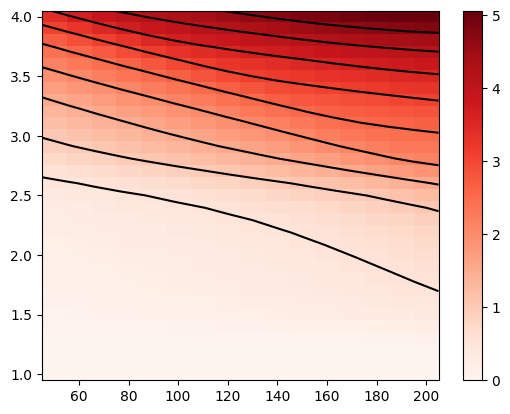

In [85]:
extent = [50-5, 200+5, 1-0.05, 4+0.05]
t = 401
D_plot = D_tot_risk[:,:,t] # D_tot_a
im = plt.imshow(D_plot,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0)
plt.contour(D_plot,np.arange(0.5,5,step=0.5), extent=extent,colors='black')
plt.colorbar(im)

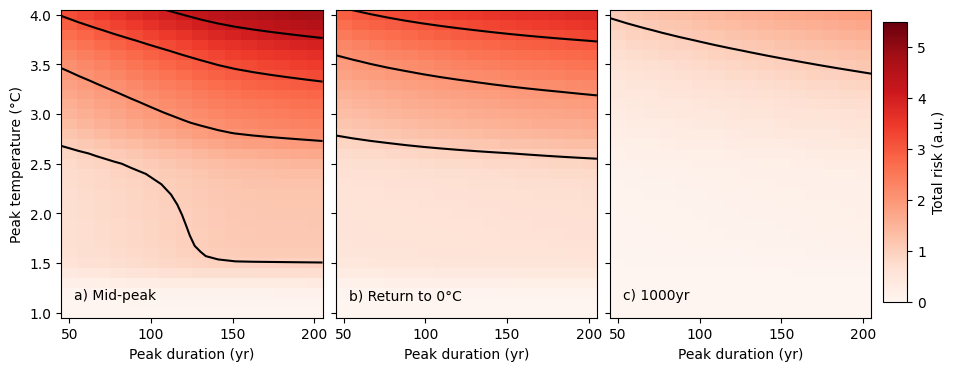

In [227]:
fig,axs = plt.subplots(ncols=3, figsize=(12,4),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)

extent = [45, 205, 1-.05, 4+.05]
axs[0].imshow(D_tot_p,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
axs[0].contour(D_tot_p,np.arange(0,6.1,step=1), extent=extent,colors='k')

axs[1].imshow(D_tot_c,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
axs[1].contour(D_tot_c,np.arange(0,6.1,step=1), extent=extent,colors='k')

im=axs[2].imshow(D_tot_risk[:,:,-1],extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
axs[2].contour(D_tot_risk[:,:,-1],np.arange(0,6.1,step=1), extent=extent,colors='k')

# letters='abc'
labels = ['a) Mid-peak', 'b) Return to 0°C', 'c) 1000yr']
for i in range(3):
    axs[i].set_xlabel('Peak duration (yr)')
    axs[i].annotate(labels[i],
                    xy=(0.05,0.05),xycoords='axes fraction',
                    ha='left',va='bottom')# for i,t in enumerate(np.arange(300,1001,step=100)):
#     D_plot = D_tot_risk[:,:,t]
#     axs[i//4,i%4].imshow(D_plot,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
#     axs[i//4,i%4].contour(D_plot,np.arange(0,6.1,step=1), extent=extent,colors='k')

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.81, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax,label='Total risk (a.u.)')

axs[0].set_ylabel('Peak temperature (°C)')
fig.savefig('../../Figures/Overshoots/T_peak_vs_t_peak.png',bbox_inches='tight')

In [109]:
t_peaks

array([ 50,  60,  70,  80,  90, 100, 110, 120, 130, 140, 150, 160, 170,
       180, 190, 200])

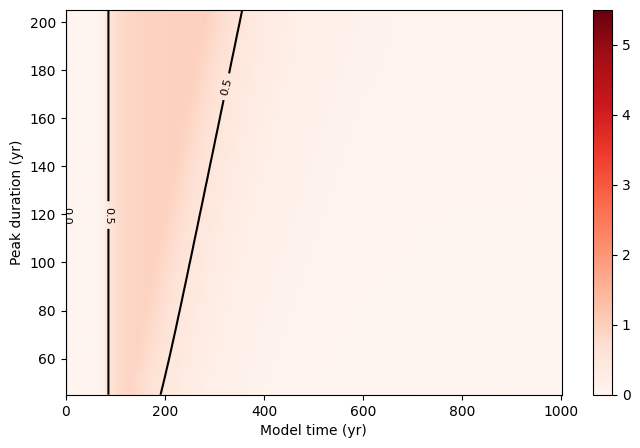

In [88]:
fig,ax=plt.subplots(figsize=(8,5))
extent = [0, 1001, 45, 205]
D_plot = D_tot_risk[5,:,:]
im = ax.imshow(D_plot,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
CS=ax.contour(D_plot,np.arange(0,5.1,step=0.5), extent=extent,colors='k')
ax.clabel(CS,fontsize=8)
fig.colorbar(im)
ax.set_ylabel("Peak duration (yr)")
ax.set_xlabel("Model time (yr)")
fig.savefig('../../Figures/Overshoots/T_peak1_5.png', bbox_inches='tight')

In [40]:
T_peaks[30]

np.float64(4.000000000000003)

Text(0.5, 0, 'Model time (yr)')

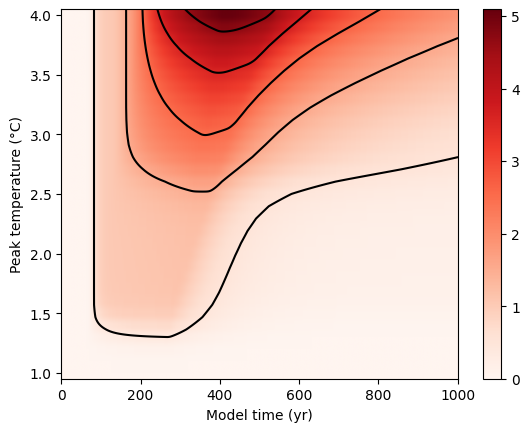

In [105]:
extent = [0, 1001, 1-.05, 4+.05]
D_plot = D_tot_risk[:,-1,:]
im = plt.imshow(D_plot,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0)
plt.contour(D_plot,np.arange(0.5,5.1,step=1), extent=extent,colors='k')
plt.colorbar(im)
plt.ylabel("Peak temperature (°C)")
plt.xlabel("Model time (yr)")

In [117]:
t_peaks[5]

np.int64(100)

In [116]:
np.where(t_peaks==50)[0][0]

np.int64(0)

In [79]:
T_peaks[5]

np.float64(2.5000000000000013)

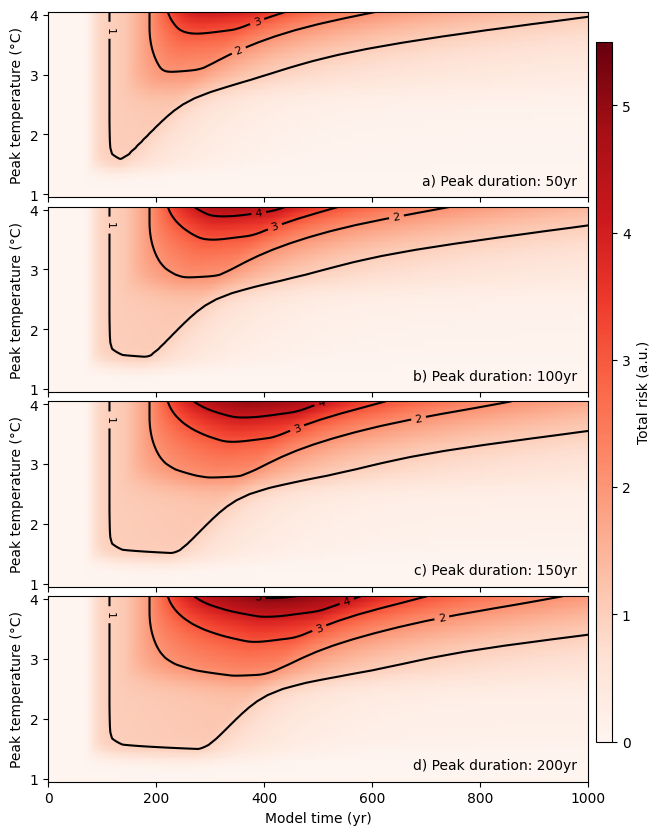

In [201]:
fig,axs=plt.subplots(nrows=4,figsize=(8,10),sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05)
extent=[0, 1000, 1-.05, 4+.05]
letters = 'abcd'
for i,t in enumerate([50,100,150,200]):
    D_plot = D_tot_risk[:,i*5,:]
    im=axs[i].imshow(D_plot,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
    CS=axs[i].contour(D_plot,np.arange(1.0,6.1,step=1), extent=extent,colors='k')
    axs[i].clabel(CS,fontsize=8)
    axs[i].annotate('%s) Peak duration: %syr'%(letters[i],t), 
                    xy=(0.98,0.05),xycoords='axes fraction',
                    ha='right',va='bottom')
    axs[i].set_ylabel('Peak temperature (°C)')

axs[-1].set_xlabel('Model time (yr)')

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.81, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax,label='Total risk (a.u.)')

fig.savefig('../../Figures/Overshoots/T_peak_vs_model_time.png',bbox_inches='tight')

In [143]:
T_peaks[30]

np.float64(4.000000000000003)

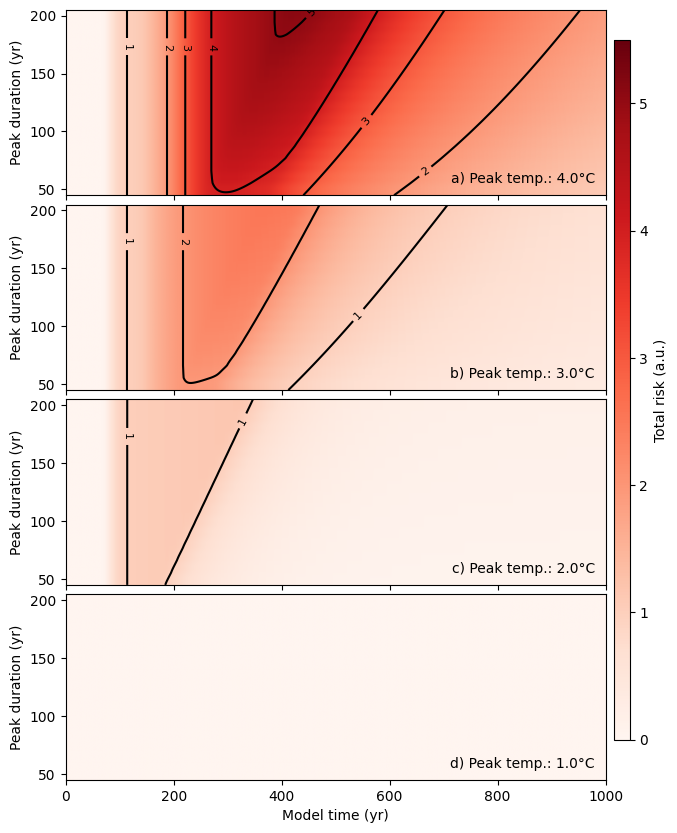

In [203]:
fig,axs=plt.subplots(nrows=4,figsize=(8,10),sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05)
extent=[0, 1000, 45, 205]
for i,t in enumerate([1,2,3,4][::-1]):
    D_plot = D_tot_risk[(3-i)*10,:,:]
    im=axs[i].imshow(D_plot,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
    CS=axs[i].contour(D_plot,np.arange(1.0,6.1,step=1), extent=extent,colors='k')
    axs[i].clabel(CS,fontsize=8)
    axs[i].set_ylabel('Peak duration (yr)')
    axs[i].annotate('%s) Peak temp.: %.1f°C'%(letters[i],t), 
                    xy=(0.98,0.05),xycoords='axes fraction',
                    ha='right',va='bottom')

axs[-1].set_xlabel('Model time (yr)')

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.81, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax,label='Total risk (a.u.)')
fig.savefig('../../Figures/Overshoots/t_peak_vs_model_time.png',bbox_inches='tight')

In [80]:
df_TEs

,Tipping element,Collapse (years),Recovery (years),Threshold (°C) – Min.,Threshold (°C) – Est.,Threshold (°C) – Max.,Beta (1/°C),Max Impact (°C) – Global,Comments
TE,,,,,,,,,
AMAZ,Amazon rainforest dieback,100,1000,2.0,3.5,6.0,4.604503,0.20,"Max impact for a total die back is 0.2C, while..."
AMOC,Atlantic meridional ocean circulation,50,500,1.4,4.0,8.0,2.656444,-0.50,NaN
ASI,Arctic winter sea ice,20,200,4.5,6.3,8.7,3.837086,0.60,NaN
ENSO,El Nino Southern Oscillation,100,1000,3.0,4.5,6.0,4.604503,0.00,From Armstrong McKay et al no estimate for max...
GIS,Greenland ice sheet,10000,100000,0.8,1.5,3.0,9.866793,0.13,NaN
PERM,Boreal permafrost collapse,50,500,3.0,4.0,6.0,6.906755,0.30,From Armstrong McKay 2022 max impact is estima...
REEF,Low-latitude coral reefs,10,100,1.0,1.5,2.0,13.813510,0.00,From Armstrong McKay et al no estimate for max...
WAIS,West Antarctic ice sheet,2000,20000,1.0,1.5,3.0,13.813510,0.05,NaN
WAM,Sahel and West African monsoon,50,500,2.0,2.8,3.5,8.633443,0.00,From Armstrong McKay et al no estimate for max...


In [36]:
D.shape

(500, 31, 16, 9, 1001)

In [34]:
D.mean(axis=0).nbytes/1e6

35.747712

## Comparing against overshoot integral

In [13]:
def overshoot_integral(t, T_peak,t_peak):
    t_ramp = T_peak/0.02
    if t < t_ramp:
        return 0.01*t**2
    elif t < t_ramp+t_peak:
        return 0.01*t_ramp**2 + (t-t_ramp)*T_peak
    elif t < 2*t_ramp + t_peak:
        return 0.01*t_ramp**2 + (t-t_ramp)*T_peak - 0.01*(t-t_ramp - t_peak)**2
    else:
        return T_peak*(t_ramp+t_peak)

In [10]:
D_mean.shape

(31, 16, 9, 1001)

In [11]:
integral = np.zeros_like(D_mean[:,:,0,:])
for i,T in enumerate(T_peaks):
    for j,t in enumerate(t_peaks):
        for k in range(1001):
            integral[i,j,k] = overshoot_integral(k,T,t)

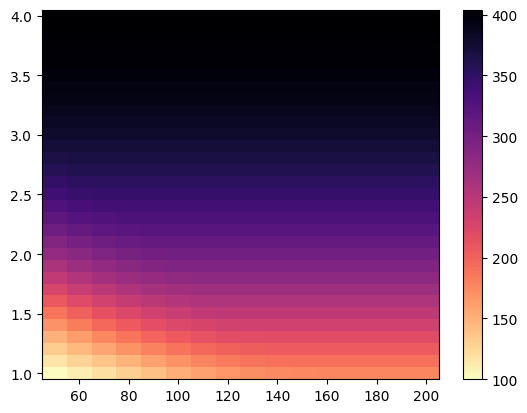

In [47]:
extent = [50-5, 200+5, 1-0.05, 4+0.05]
t = 201
im = plt.imshow(integral[:,:,t],extent=extent,origin='lower',aspect='auto',cmap='magma_r')
plt.colorbar(im)

In [48]:
integral.shape

(31, 16, 1001)

In [49]:
D_mean.shape

(31, 16, 9, 1001)

In [16]:
import matplotlib

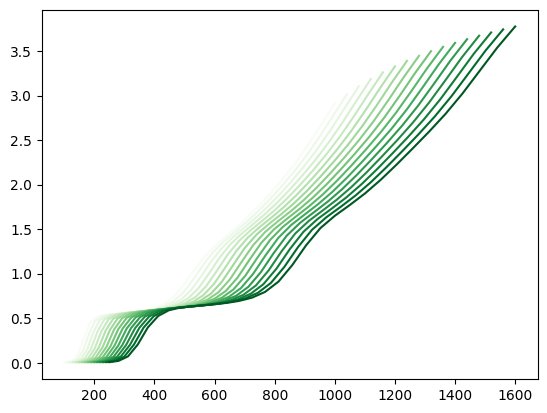

In [23]:
cmap = matplotlib.colormaps['Greens']
for j,t in enumerate(t_peaks):
    os_ints = np.array([T*(T/0.02 + t) for i,T in enumerate(T_peaks)])
    plt.plot(os_ints,[D_tot_risk[i,j,round(T/0.01)+t] for i,T in enumerate(T_peaks)],color=cmap(j/len(t_peaks)))

Text(0, 0.5, 'Peak temperature (°C)')

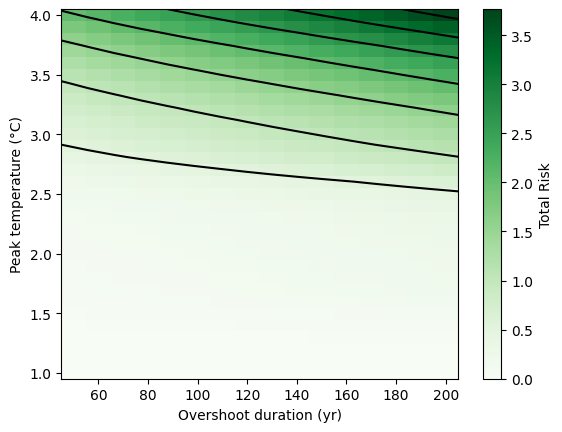

In [85]:
extent = [50-5, 200+5, 1-0.05, 4+0.05]
t = 601
im = plt.imshow(D_tot_risk[:,:,t],extent=extent,origin='lower',aspect='auto',cmap='Greens',vmin=0)
plt.contour(D_tot_risk[:,:,t],np.arange(0.5,5,step=0.5), extent=extent,colors='black')
plt.colorbar(im,label='Total Risk')
plt.xlabel('Overshoot duration (yr)')
plt.ylabel('Peak temperature (°C)')

In [61]:
D_tot_a.shape

(31, 16)

# Convergent temperature at 1.5C

In [5]:
t_peaks = np.arange(50,201,step=10)
T_peaks = np.arange(1.5,4.1,step=0.1)
t_end=1000

Temp = np.array( [[TIPMIP_temps(T_peak=T,t_peak=t,t_end=t_end,T_conv=1.5) for t in t_peaks] for T in T_peaks])

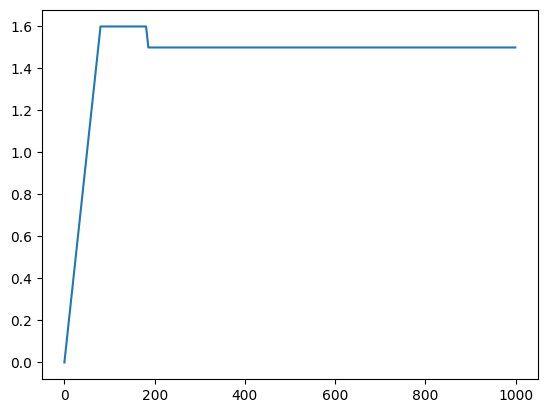

In [6]:
plt.plot(TIPMIP_temps(T_peak=1.6,t_peak=100,T_conv=1.5,t_end=1000))

## running sims

In [7]:
D = np.zeros((len_sample, len(T_peaks), len(t_peaks), len(df_TEs), t_end+1))
for r in tqdm.tqdm(range(len_sample)):
    for i,T_p in enumerate(T_peaks):
        for j,t_p in enumerate(t_peaks):
            for t in range(1,t_end+1):
                # environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])
                D[r, i, j, :, t] =  environmental_update(D[r, i, j, :, t-1], A[r], 
                                                      pc=q_c*temp_response(Temp[i,j,t-1], T_lim, betas),
                                                      pr=q_r*(1-temp_response(Temp[i,j,t-1], T_lim, betas)))

100%|██████████████████████████████████████████████████████████████████████████████| 500/500 [1:03:17<00:00,  7.59s/it]


In [8]:
D_mean = D.mean(axis=0)
for i,T in enumerate(T_peaks):
    for j,t in enumerate(t_peaks):
        np.savetxt("../../Data/Simulations/Overshoots/T_conv_1_5/T%.1f_t%s.csv"%(T,t), D_mean[i,j,:,:])

## loading sims

In [3]:
t_peaks = np.arange(50,201,step=10)
T_peaks = np.arange(1.5,4.1,step=0.1)
D_mean = np.array([[np.loadtxt("../../Data/Simulations/Overshoots/T_conv_1_5/T%.1f_t%s.csv"%(T,t)) 
           for j,t in enumerate(t_peaks)] 
          for i,T in enumerate(T_peaks)])

In [4]:
D_tot_risk = D_mean.sum(axis=2)

D_tot_a = np.array([[D_tot_risk[i,j,round(50*T)] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_b = np.array([[D_tot_risk[i,j,round(50*T+t)] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_c = np.array([[D_tot_risk[i,j,round(100*T)+t-75] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_d = np.array([[D_tot_risk[i,j,round(100*T)+t-75+100] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_p = np.array([[D_tot_risk[i,j,round(50*T)+round(t/2)] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])

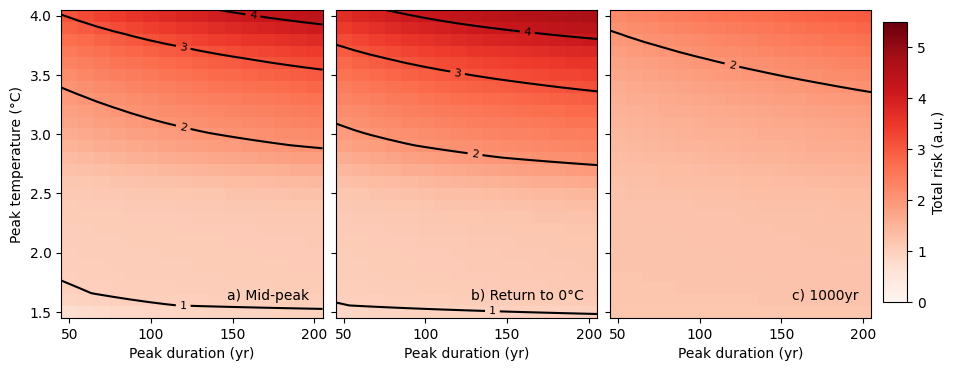

In [18]:
fig,axs = plt.subplots(ncols=3, figsize=(12,4),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)

extent = [45, 205, 1.5-.05, 4+.05]
axs[0].imshow(D_tot_p,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
cs=axs[0].contour(D_tot_p,np.arange(0,6.1,step=1), extent=extent,colors='k')
axs[0].clabel(cs,fontsize=8)

axs[1].imshow(D_tot_c,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
cs=axs[1].contour(D_tot_c,np.arange(0,6.1,step=1), extent=extent,colors='k')
axs[1].clabel(cs,fontsize=8)

im=axs[2].imshow(D_tot_risk[:,:,-1],extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
cs=axs[2].contour(D_tot_risk[:,:,-1],np.arange(0,6.1,step=1), extent=extent,colors='k')
axs[2].clabel(cs,fontsize=8)

# letters='abc'
labels = ['a) Mid-peak', 'b) Return to 0°C', 'c) 1000yr']
for i in range(3):
    axs[i].set_xlabel('Peak duration (yr)')
    axs[i].annotate(labels[i],
                    xy=(0.95,0.05),xycoords='axes fraction',
                    ha='right',va='bottom')# for i,t in enumerate(np.arange(300,1001,step=100)):
#     D_plot = D_tot_risk[:,:,t]
#     axs[i//4,i%4].imshow(D_plot,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
#     axs[i//4,i%4].contour(D_plot,np.arange(0,6.1,step=1), extent=extent,colors='k')

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.81, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax,label='Total risk (a.u.)')

axs[0].set_ylabel('Peak temperature (°C)')
fig.savefig('../../Figures/Overshoots/T_conv1_5_T_peak_vs_t_peak.png',bbox_inches='tight')

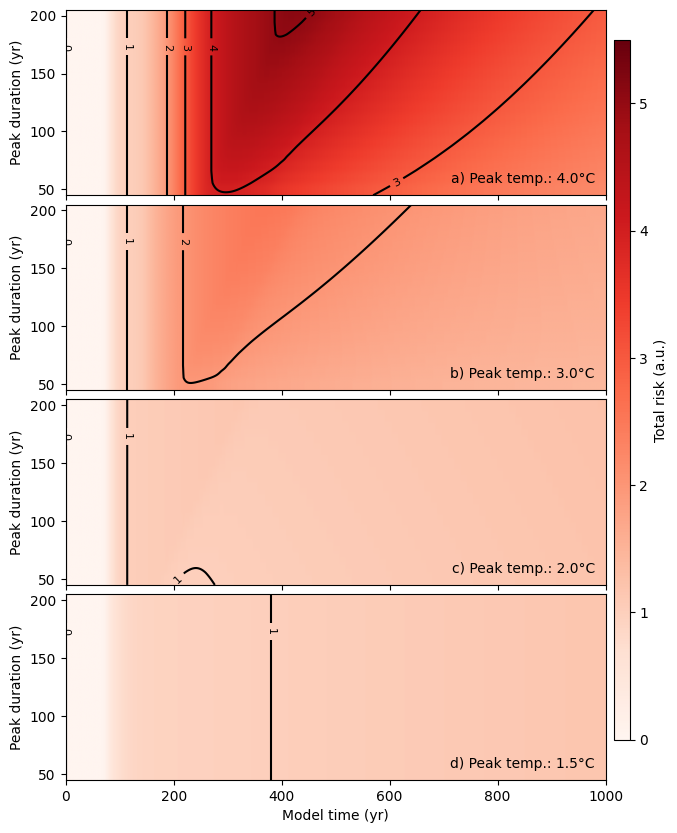

In [11]:
fig,axs=plt.subplots(nrows=4,figsize=(8,10),sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05)
extent=[0, 1000, 45, 205]
letters='abcd'
indices = [0,5,15,25]
T_to_plot = [1.5,2,3,4]
for i,T in enumerate(T_to_plot):
    D_plot = D_tot_risk[indices[3-i],:,:]
    im=axs[i].imshow(D_plot,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
    CS=axs[i].contour(D_plot,np.arange(0,6.1,step=1), extent=extent,colors='k')
    axs[i].clabel(CS,fontsize=8)
    axs[i].set_ylabel('Peak duration (yr)')
    axs[i].annotate('%s) Peak temp.: %.1f°C'%(letters[i],T_to_plot[3-i]), 
                    xy=(0.98,0.05),xycoords='axes fraction',
                    ha='right',va='bottom')

axs[-1].set_xlabel('Model time (yr)')

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.81, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax,label='Total risk (a.u.)')
fig.savefig('../../Figures/Overshoots/T_conv1_5_t_peak_vs_model_time.png',bbox_inches='tight')

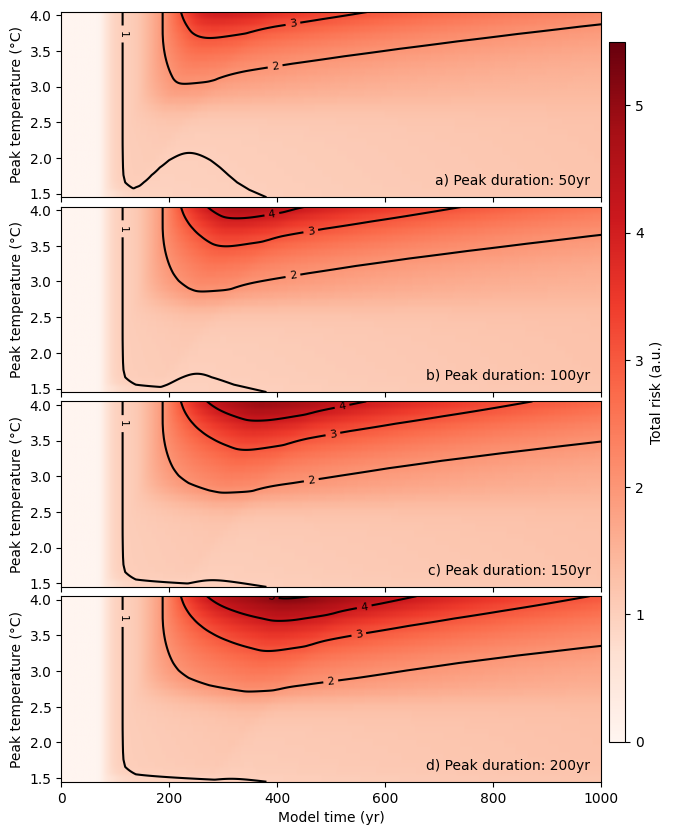

In [13]:
fig,axs=plt.subplots(nrows=4,figsize=(8,10),sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05)
extent=[0, 1000, 1.5-.05, 4+.05]
letters = 'abcd'
for i,t in enumerate([50,100,150,200]):
    D_plot = D_tot_risk[:,i*5,:]
    im=axs[i].imshow(D_plot,extent=extent,origin='lower',aspect='auto',cmap='Reds',vmin=0,vmax=5.5)
    CS=axs[i].contour(D_plot,np.arange(1.0,6.1,step=1), extent=extent,colors='k')
    axs[i].clabel(CS,fontsize=8)
    axs[i].annotate('%s) Peak duration: %syr'%(letters[i],t), 
                    xy=(0.98,0.05),xycoords='axes fraction',
                    ha='right',va='bottom')
    axs[i].set_ylabel('Peak temperature (°C)')

axs[-1].set_xlabel('Model time (yr)')

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.81, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax,label='Total risk (a.u.)')

fig.savefig('../../Figures/Overshoots/T_conv1_5_T_peak_vs_model_time.png',bbox_inches='tight')

In [37]:
T_peaks

array([1.5, 1.6, 1.7, 1.8, 1.9, 2. , 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7,
       2.8, 2.9, 3. , 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4. ])

In [38]:
np.where(T_peaks==2.0)

(array([], dtype=int64),)

## drawing illustrative diagram

In [14]:
t_peaks

array([ 50,  60,  70,  80,  90, 100, 110, 120, 130, 140, 150, 160, 170,
       180, 190, 200])

In [22]:
T_peak = 2.3
t_peak = 80
temp_to_plot = TIPMIP_temps(T_peak=T_peak,t_peak=t_peak,T_conv=1.5,t_end=1000)

In [43]:
print(T_peaks[round(T_peak*10)-15])
print(t_peaks[round(t_peak/10)-5])

2.3000000000000007
80


Text(0, 0.5, 'Coral reef risk')

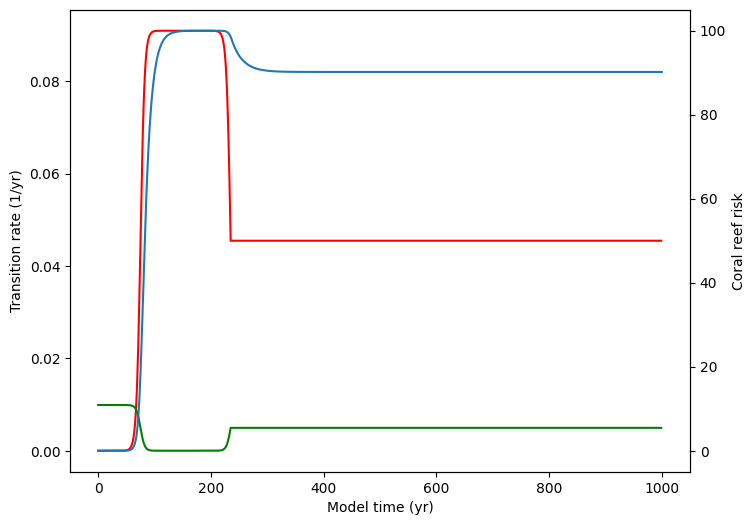

In [54]:
fig,ax = plt.subplots(figsize=(8,6))
ax.plot(q_c[-3]*util.dynamics.temp_response(temp_to_plot,T_lim[-3],beta=betas[-3]), color='red',label='Collapse')
ax.plot(q_r[-3]*(1-util.dynamics.temp_response(temp_to_plot,T_lim[-3],beta=betas[-3])), color='green',label='Recovery')
# ax.plot(D_mean[round(T_peak*10)-15, round(t_peak/10)-5,-3,:], label='Coral reef risk')
ax.set_xlabel("Model time (yr)")
ax.set_ylabel("Transition rate (1/yr)")
# ax.set_ylim([0,1])

ax_temp = ax.twinx()
ax_temp.tick_params(axis='y')
# ax_temp.plot(temp_to_plot,color='k')
ax_temp.plot(D_mean[round(T_peak*10)-15, round(t_peak/10)-5,-3,:]*100, label='Coral reef risk')
ax_temp.set_ylabel("Coral reef risk")
# ax_temp.set_ylim([0,6])
# fig.legend()

In [21]:
help(util.dynamics.temp_response)

Help on function temp_response in module util.dynamics:

temp_response(T, T_lim, beta)
    Returns the response in collapse rate to a temperature T,
    for a tipping element with threshold T_lim and temperature sensitivity (i.e. logistic parameter) beta

    Parameters
    ---
    T : numpy.array or float
        Temperature(s)
    T_lim : numpy.array or float
        Tipping/critical threshold(s)
    beta : numpy.array or something broadcastable
        Temperature sensitivity(ies) (i.e. logistic parameter)

    Returns
    ---
    out : numpy.array



In [31]:
D_mean.shape

(26, 16, 9, 1001)

In [34]:
t_peaks

array([ 50,  60,  70,  80,  90, 100, 110, 120, 130, 140, 150, 160, 170,
       180, 190, 200])

In [33]:
T_peaks[round(T_peak*10)-15]

np.float64(2.3000000000000007)

## Plot for adding an additional 0.1C

In [59]:
np.diff(D_tot_risk,axis=0).shape

(25, 16, 1001)

In [97]:
T_peaks

array([1.5, 1.6, 1.7, 1.8, 1.9, 2. , 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7,
       2.8, 2.9, 3. , 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4. ])

In [110]:
temp_to_plot[75]

np.float64(1.5)

In [112]:
D_tot_risk[:,:,76:].shape

(26, 16, 925)

In [117]:
1001-76+1

926

In [114]:
print(np.arange(1002,step=1))

[   0    1    2 ...  999 1000 1001]


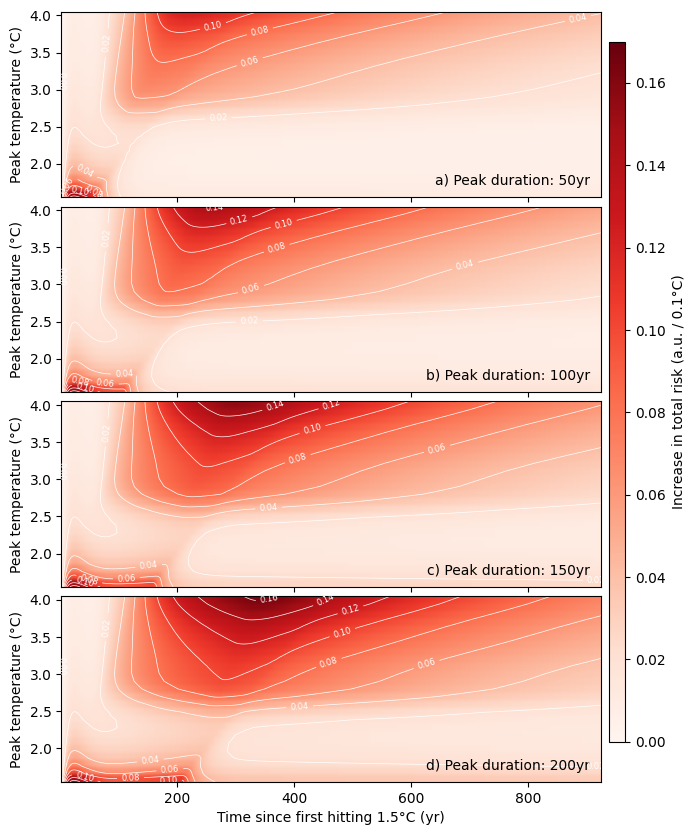

In [22]:
fig,axs=plt.subplots(nrows=4,figsize=(8,10),sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05)
extent=[0-0.5-75, 1000+0.5-75, 1.6-.05, 4+.05]
letters = 'abcd'
for i,t in enumerate([50,100,150,200]):
    # D_plot = np.diff(D_tot_risk,axis=0)[:,i*5,75:]*100
    D_plot = (D_tot_risk[1:,i*5,:] - D_tot_risk[0,i*5,:])/(T_peaks[1:]-1.5).reshape(25,1)/10
    im=axs[i].imshow(D_plot,extent=extent,origin='lower',aspect='auto',
                     cmap='Reds',vmin=0,vmax=1.7/10)
    CS=axs[i].contour(D_plot,np.arange(0,1.8/10,step=0.2/10), extent=extent,colors='white',linewidths=0.5)
    axs[i].clabel(CS,fontsize=6)
    axs[i].annotate('%s) Peak duration: %syr'%(letters[i],t), 
                    xy=(0.98,0.05),xycoords='axes fraction',
                    ha='right',va='bottom')
    axs[i].set_ylabel('Peak temperature (°C)')

axs[-1].set_xlabel('Time since first hitting 1.5°C (yr)')
axs[-1].set_xlim([76-75,1000-75])

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.81, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax,label=r'Increase in total risk (a.u. / 0.1°C)')
# cbar_ax.set_ylim(0,37)

fig.savefig('../../Figures/Overshoots/T_conv1_5/RiskIncreaseAbove1_5C.png',bbox_inches='tight')

In [7]:
D_plot.min()

np.float64(0.0)

## per additional decade

In [130]:
len(t_peaks)

16

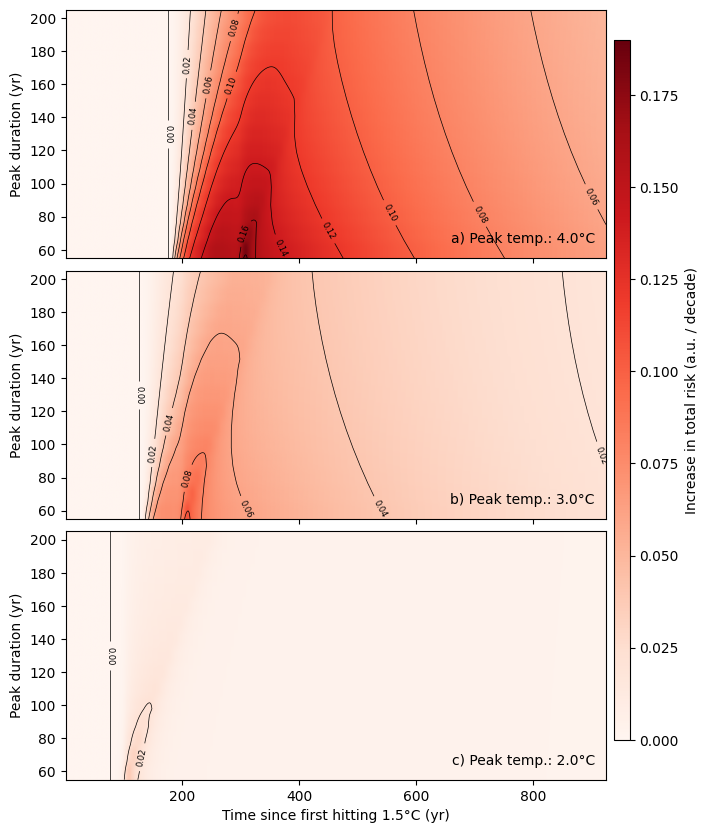

In [19]:
T_to_plot = [2,3,4]
indices = [round(T*10)-15 for T in T_to_plot]
nrows = len(T_to_plot)
fig,axs=plt.subplots(nrows=nrows,figsize=(8,10),sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05)
extent=[0-0.5-75, 1000+0.5-75, 55, 205]
letters='abcd'
# indices = [0,5,15,25]
# T_to_plot = [1.5,2,3,4]
for i,T in enumerate(T_to_plot):
    D_plot = (D_tot_risk[indices[nrows-1-i],1:,:] - D_tot_risk[indices[nrows-1-i],0,:])/(np.arange(10,151,step=10).reshape(15,1)/10)
    im=axs[i].imshow(D_plot,extent=extent,origin='lower',aspect='auto',cmap='Reds',
                     vmin=0,vmax=0.19)
    CS=axs[i].contour(D_plot,np.arange(0.0,0.19,step=0.02), extent=extent,
                      colors='k',linewidths=0.5)
    axs[i].clabel(CS,fontsize=6)
    axs[i].set_ylabel('Peak duration (yr)')
    axs[i].annotate('%s) Peak temp.: %.1f°C'%(letters[i],T_to_plot[nrows-1-i]), 
                    xy=(0.98,0.05),xycoords='axes fraction',
                    ha='right',va='bottom')

axs[-1].set_xlabel('Time since first hitting 1.5°C (yr)')
axs[-1].set_xlim([76-75,1000-75])

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.81, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax,label='Increase in total risk (a.u. / decade)')
fig.savefig('../../Figures/Overshoots/T_conv1_5/RiskIncreaseAbove50yrs.png',bbox_inches='tight')

In [10]:
D_plot.max()

np.float64(0.0374320044958123)

In [13]:
i=0
D_plot = (D_tot_risk[indices[nrows-1-i],1:,:] - D_tot_risk[indices[nrows-1-i],0,:])/(np.arange(10,151,step=10).reshape(15,1)/10)
D_plot.max()

np.float64(0.1829023318377554)